# I-V Map

interactive slider

data: 2024/05/08

2026/4/1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial']
import h5py
import os

In [2]:
# source
root_path  ='/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"

h5map_path = os.path.join(root_path, filename)

# 使用新的 HDF5Analyzer
from ivs_tools import HDF5Analyzer

# 初始化 (自動載入)
h5map = HDF5Analyzer(h5map_path)

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

h5map.print_usage()

DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------
HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
----------------------------------------
  • load_metadata(): 加載元數據
  • load_current_map(): 加載電流映射
  • load_bias_vector(): 加載偏壓序列
  • l

In [3]:
h5map.metadata

HDF5Metadata(bias_points=500, x_pixels=100, y_pixels=100, x_range=1.999998e-06, y_range=1.9999969999999996e-06, experiment_type='Bias-Spectroscopy-Current-Map-fwd', unit='m', raw_metadata={'ExpDate': '08.05.2024', 'dataSize': 500, 'lineofHeader': 19})

Plot saved to: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/plots/2 um 100 pix bias spec map2_20260402_114724_correlated.png


PosixPath('/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/plots/2 um 100 pix bias spec map2_20260402_114724_correlated.png')

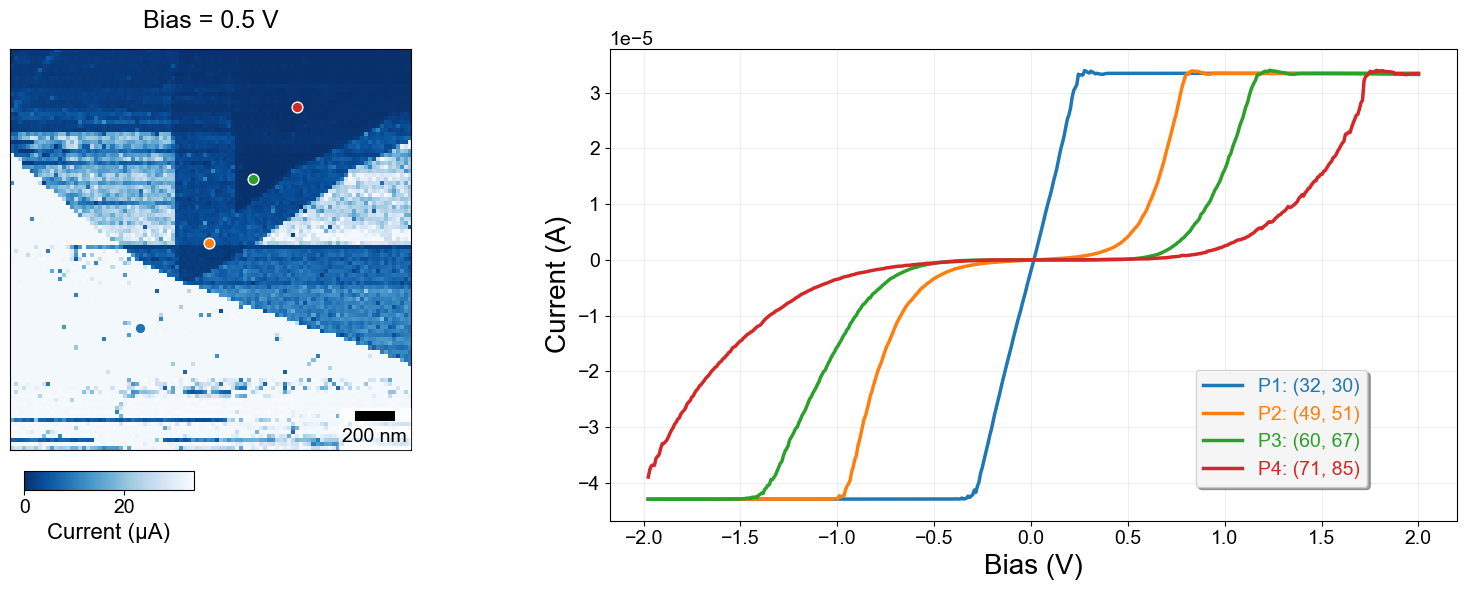

In [4]:
#from h5_coplotter import CorrelatedPlotter
from ivs_tools.viz import CorrelatedPlotter
from pathlib import Path

plotter = CorrelatedPlotter(h5map)

# 定義點
points = [(32, 30), (49, 51), (60, 67), (71, 85)]

 # 創建圖表
fig, colors = plotter.create_correlated_plot(
    bias_value=0.5,
    points=points,
    islogy=False,
    start_idx=3,
    colormap='Set2'
)

h5map_path = Path(h5map_path)
output_dir = h5map_path.parent / 'plots'
plotter.save_plot_with_timestamp(
    fig, 
    output_dir=output_dir,
    base_name=h5map_path.stem,
    islogy=False
)

## Histogram

In [5]:
from pathlib import Path

In [6]:
bias_map = h5map.get_2d_map_at_bias(bias_slice)


fig, ax = plt.subplots(1, 2, figsize = (14,6))

desired_vmin =  np.percentile(bias_map, 2)
desired_vmax = np.percentile(bias_map, 98)

heatmap = ax[0].imshow(bias_map,
                    aspect='equal',
                    origin='lower',
                    cmap = 'Blues_r',
                    vmin=desired_vmin, 
                    vmax=desired_vmax
                   )

cbar = fig.colorbar(heatmap, ax=ax[0], orientation='horizontal',
                    pad=0,
                    aspect = 9,
                    shrink=0.2,
                    anchor=(0.26, 0.6)
                   )

cbar.ax.tick_params(labelsize=16)

ax[0].set_xticks([]) 
ax[0].set_yticks([]) 
ax[0].set_title(f"", fontsize = 18)

pixel_size = metadata.x_range/metadata.x_pixels # in meter

pixel_size_in_nanometers = pixel_size*1e9

scalebar = ScaleBar(pixel_size_in_nanometers, 'nm',
                    length_fraction=0.2, 
                    height_fraction=0.02, # Height of the scale bar as a fraction of the axis height
                    location='lower left', # Position (e.g., 'lower right', 'upper left')
                    box_color='white', 
                    box_alpha=0.0, 
                    color='black', 
                    font_properties={'size': 15}) 

ax[0].add_artist(scalebar)

data_flat = bias_map.flatten()
median_val = np.median(data_flat)
mean_val = np.mean(data_flat)
print('median: ', median_val)
print('mean: \t', mean_val)

# 绘制直方图
counts, bins, patches = ax[1].hist(data_flat, bins=70, alpha=0.7, color='tab:blue', edgecolor='white', log=True)
ax[1].set_xlabel('Value', fontsize = 25)
ax[1].set_ylabel('Frequency', fontsize = 25)
ax[1].axvline(median_val, lw =3, c = 'tab:red', label = "median")
ax[1].axvline(mean_val, lw =3, c = 'tab:orange',label = "mean")
ax[1].axvline(desired_vmin, lw =3, c = 'tab:green',label = "vmin")
ax[1].axvline(desired_vmax, lw =3, c = 'tab:pink',label = "vmax")
ax[1].tick_params(axis = 'both', labelsize = 15)
ax[1].grid(True, alpha=0.3)
#ax[1].set_yscale('log')
#ax[1].set_xscale('log')
ax[1].legend(frameon = True, fontsize = 15)

plt.tight_layout()

h5map_path = Path(h5map_path) 
output_filename = h5map_path.with_suffix('._cur_stats_matplot.png')

plt.savefig(output_filename, dpi=500, bbox_inches = 'tight')

plt.show()

NameError: name 'bias_slice' is not defined

## Overlay

In [10]:
import gwyfile
filename = '/home/tim/Documents/AS/data/nanonis2/2024/20240508/Mos2_au_normT_0013.sxm.gwy'
gwy_obj = gwyfile.load(filename)

channels = gwyfile.util.get_datafields(gwy_obj)
keys = list(channels.keys())
channel = channels["Current (Forward)"]
gwy_data = channel.data

In [17]:
bias_map = h5map.get_2d_map_at_bias(0.3)
metadata = h5map.metadata

bias_map shape: (100, 100)
gwy_data shape: (256, 256)


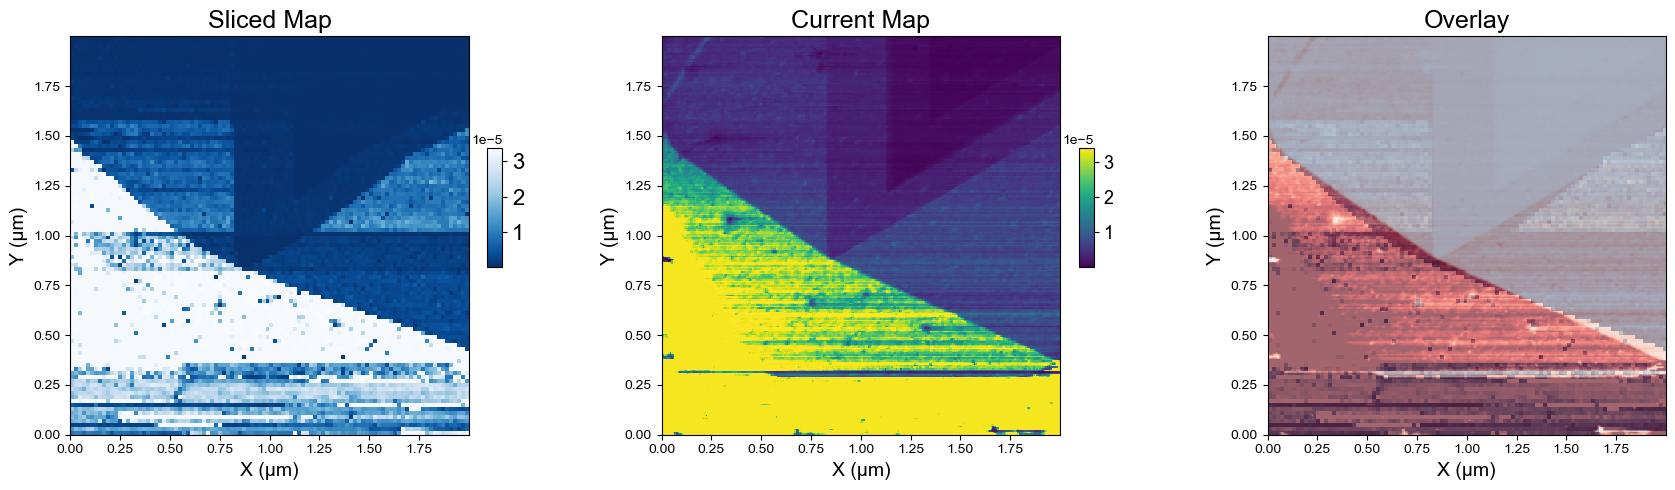

In [18]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 確認兩個數據的原始形狀
print(f"bias_map shape: {bias_map.shape}")
print(f"gwy_data shape: {gwy_data.shape}")

# ---- First subplot: bias_map ----
desired_vmin = np.percentile(bias_map, 2)
desired_vmax = np.percentile(bias_map, 98)

# 使用 extent 參數來定義實際物理範圍
# 假設兩個數據的物理範圍相同，都從 (0,0) 到 (1,1)
extent = [0, metadata.x_range*1e6, 0, metadata.y_range*1e6]  # [left, right, bottom, top]

heatmap1 = ax[0].imshow(bias_map,
                        aspect='equal',
                        origin='lower',
                        cmap='Blues_r',
                        vmin=desired_vmin,
                        vmax=desired_vmax,
                        extent=extent)  # 添加 extent 參數
cbar1 = fig.colorbar(heatmap1, ax=ax[0], pad=0, aspect=8, shrink=0.3, anchor=(0.29, 0.6))
cbar1.ax.tick_params(labelsize=16)
ax[0].set_title("Sliced Map", fontsize=18)
ax[0].set_xlabel("X (μm)", fontsize=14)
ax[0].set_ylabel("Y (μm)", fontsize=14)

# ---- Second subplot: gwy_data ----
heatmap2 = ax[1].imshow(gwy_data,
                        interpolation='none',
                        origin='upper',
                        extent=extent)  # 使用相同的 extent
cbar2 = fig.colorbar(heatmap2, ax=ax[1], pad=0, aspect=8, shrink=0.3, anchor=(0.29, 0.6))
cbar2.ax.tick_params(labelsize=13)
ax[1].set_title("Current Map", fontsize=18)
ax[1].set_xlabel("X (μm)", fontsize=14)
ax[1].set_ylabel("Y (μm)", fontsize=14)

# ---- Third subplot: overlay ----
# 兩個圖層使用相同的 extent
ax[2].imshow(bias_map, cmap='Blues_r', 
             origin='lower', 
             alpha=0.9,
             extent=extent)

ax[2].imshow(gwy_data, cmap='Reds', 
             origin='upper', 
             alpha=0.6,
             extent=extent)

ax[2].set_title("Overlay", fontsize=18)
ax[2].set_xlabel("X (μm)", fontsize=14)
ax[2].set_ylabel("Y (μm)", fontsize=14)

plt.tight_layout()

h5map_path = Path(h5map_path) 
output_filename = h5map_path.with_suffix('._ivmap_curmap_compare_matplot.png')

plt.savefig(output_filename, dpi=500, bbox_inches = 'tight')

plt.show()

In [17]:
h5map.current_map

array([[ 3.2221451e-05,  3.3260734e-05,  3.1130396e-05, ...,
         3.6547272e-07,  3.9937026e-07,  2.8371596e-07],
       [-4.2104191e-05, -3.8033821e-05, -4.2859883e-05, ...,
        -3.5860008e-05, -3.5723850e-05, -3.6706806e-05],
       [-4.2887870e-05, -4.2882803e-05, -4.2878302e-05, ...,
        -4.0526160e-05, -3.9097675e-05, -4.0230781e-05],
       ...,
       [ 3.3369866e-05,  3.3347740e-05,  3.3361746e-05, ...,
         2.4944025e-05,  2.3855615e-05,  2.3307930e-05],
       [ 3.3368859e-05,  3.3344950e-05,  3.3365061e-05, ...,
         2.5743204e-05,  2.4637033e-05,  2.3669396e-05],
       [ 3.3366006e-05,  3.3340784e-05,  3.3357279e-05, ...,
         2.6237802e-05,  2.5318504e-05,  2.4178536e-05]],
      shape=(500, 10000))

In [ ]:
h5map.metadata.x_pixels

## Interactive slider

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, Checkbox, Dropdown, VBox, HBox, Output, interactive
from IPython.display import display, clear_output
%matplotlib ipympl 

def create_3d_viewer(analyzer):
    """
    在滑块描述中动态显示bias值
    """
    
    # 获取数据信息
    bias_points = analyzer.current_map.shape[0]
    x_pixels = analyzer.metadata.x_pixels
    y_pixels = analyzer.metadata.y_pixels
    
    # 检查是否有bias数据
    has_bias = hasattr(analyzer, 'bias_vector')
    if has_bias:
        bias_data = analyzer.bias_vector
    else:
        bias_data = np.arange(bias_points)
    
    # 输出区域
    output = Output()
    
    # 创建滑块
    bias_slider = IntSlider(
        min=0,
        max=bias_points-1,
        value=bias_points//2,
        description='Bias:',
        continuous_update=False,
        readout=False,  # 关闭默认的数值显示
        style={'description_width': 'initial'},
        layout={'width': '400px'}
    )
    
    # 更新滑块描述
    def update_slider_description(bias_index):
        if has_bias:
            bias_value = bias_data[bias_index]
            bias_slider.description = f"Bias: {bias_value:.3f} V (Index: {bias_index})"
        else:
            bias_slider.description = f"Bias Index: {bias_index}"
    
    # 连接事件
    def on_bias_change(change):
        update_slider_description(change['new'])
    
    bias_slider.observe(on_bias_change, names='value')
    
    # 初始更新
    update_slider_description(bias_slider.value)
           
    # 选中的像素位置
    selected_pixel = {'x': x_pixels // 2, 'y': y_pixels // 2}
    click_handlers = []  # 存储点击事件处理器
    
    log_checkbox = Checkbox(
        value=False,
        description='Log Scale',
        style={'description_width': 'initial'}
    )
    
    cmap_dropdown = Dropdown(
        options=['Blues_r', 'viridis', 'plasma', 'inferno', 'magma', 'coolwarm', 'RdBu', 'seismic', 'jet'],
        value='Blues_r',
        description='Colormap:',
        style={'description_width': 'initial'}
    )
    
    pixel_x_slider = IntSlider(
        min=0,
        max=x_pixels-1,
        value=x_pixels//2,
        description='Pixel X:',
        continuous_update=False,
        style={'description_width': 'initial'}
    )
    
    pixel_y_slider = IntSlider(
        min=0,
        max=y_pixels-1,
        value=y_pixels//2,
        description='Pixel Y:',
        continuous_update=False,
        style={'description_width': 'initial'}
    )
    
    # 更新函数
    def update_plot(bias_index, log_scale, cmap, pixel_x, pixel_y):
        """
        更新图形显示
        """
        with output:
            clear_output(wait=True)
            
            try:
                # 更新选中的像素
                selected_pixel['x'] = min(max(0, pixel_x), x_pixels - 1)
                selected_pixel['y'] = min(max(0, pixel_y), y_pixels - 1)
                
                x_pix, y_pix = selected_pixel['x'], selected_pixel['y']
                
                # 更新滑块值以保持一致
                pixel_x_slider.value = x_pix
                pixel_y_slider.value = y_pix
                
                # 获取当前切片数据
                current_1d = analyzer.current_map[bias_index, :]
                
                # 重塑为2D
                try:
                    current_2d = current_1d.reshape(y_pixels, x_pixels)
                except:
                    current_2d = current_1d.reshape(x_pixels, y_pixels)
                
                # 创建图形
                fig, axes = plt.subplots(1, 2, figsize=(14, 6), 
                                         gridspec_kw={'width_ratios': [1, 1.5]}
                                        )
                # 左侧：电流映射
                ax1 = axes[0]
                
                # 处理对数尺度
                if log_scale:
                    with np.errstate(divide='ignore', invalid='ignore'):
                        plot_data = np.where(current_2d > 0, np.log10(current_2d), np.nan)
                    color_label = 'Log10(Current)'
                else:
                    plot_data = current_2d
                    color_label = 'Current (A)'
                
                # 显示图像
                im1 = ax1.imshow(plot_data, 
                               cmap=cmap,
                               origin='lower',
                               aspect='equal')
                
                # 标记选中的像素
                ax1.plot(x_pix, y_pix, 'ro', markersize=9, 
                        markeredgecolor='white', linewidth=2, alpha=0.8)
                
                ax1.set_title(f'Current Map (Bias Index: {bias_data[bias_index]})')
                ax1.set_xticks([])
                ax1.set_yticks([])
                plt.colorbar(im1, ax=ax1, shrink = 0.3, aspect = 8, orientation='horizontal', pad = 0.02)
                
                # 右侧：I-V 曲线
                ax2 = axes[1]
                
                # 获取选中像素的索引
                pixel_index = y_pix * x_pixels + x_pix
                
                if pixel_index < analyzer.current_map.shape[1]:
                    # 获取该像素的完整 I-V 数据
                    iv_current = analyzer.current_map[3:, pixel_index] # skip 3 points
                    
                    # 绘制 I-V 曲线
                    ax2.plot(bias_data[3:], iv_current, '-', c = 'tab:blue', linewidth=3, label='I-V Curve')
                    
                    # 标记当前偏压点
                    current_bias = bias_data[bias_index]
                    current_value = iv_current[bias_index]
                    
                    ax2.plot(current_bias, current_value, 'ro', markersize=6, 
                            label=f'Current: {current_value:.2e} A')
                    
                    ax2.set_xlabel('Bias Voltage (V)' if has_bias else 'Bias Index', fontsize = 18)
                    ax2.set_ylabel('Current (A)', fontsize = 18)
                    ax2.set_title(f'I-V Curve at Pixel ({x_pix}, {y_pix})', fontsize = 20)
                    ax2.tick_params(labelsize = 12) 
                    ax2.legend(loc='upper left')
                    ax2.grid(True, alpha=0.3)
                                    
                plt.tight_layout()
                plt.show()
                
                # 打印信息
                print(f"Selected Pixel: ({x_pix}, {y_pix})")
                print(f"Current Value: {current_2d[y_pix, x_pix]:.3e} A")
                print(f"Bias Index: {bias_index}")
                
                # 设置点击事件 - 重新创建图形后需要重新绑定
                def on_click(event):
                    if event.inaxes == ax1:
                        # 获取点击位置
                        x = int(event.xdata + 0.5)
                        y = int(event.ydata + 0.5)
                        
                        # 确保在范围内
                        x = max(0, min(x, x_pixels - 1))
                        y = max(0, min(y, y_pixels - 1))
                        
                        print(f"點擊位置: ({x}, {y})")
                        
                        # 更新显示
                        update_plot(bias_index, log_scale, cmap, x, y)
                
                # 移除旧的点击处理器
                for handler in click_handlers:
                    try:
                        fig.canvas.mpl_disconnect(handler)
                    except:
                        pass
                
                # 添加新的点击处理器
                click_handlers.append(fig.canvas.mpl_connect('button_press_event', on_click))
                
            except Exception as e:
                print(f"更新圖形時出錯: {e}")
                import traceback
                traceback.print_exc()
    
    # 创建控制面板
    controls = VBox([
        HBox([bias_slider]),
        HBox([log_checkbox, cmap_dropdown]),
        HBox([pixel_x_slider, pixel_y_slider])
    ])
    
    # 使用interactive而不是interact，避免重复顯示控件
    ui = interactive(update_plot,
                     bias_index=bias_slider,
                     log_scale=log_checkbox,
                     cmap=cmap_dropdown,
                     pixel_x=pixel_x_slider,
                     pixel_y=pixel_y_slider)
    
    # 只显示一次控件和输出区域
    display(controls)
    display(output)
    
    # 初始化顯示
    update_plot(bias_slider.value, 
               log_checkbox.value, 
               cmap_dropdown.value,
               pixel_x_slider.value,
               pixel_y_slider.value)
    
    #return ui

# 使用方法
create_3d_viewer(h5map)

Output()

## Static plot

Plot saved to: /home/tim/Documents/AS/data/nanonis2/20240508/2 um 100 pix bias spec map2/plots/2 um 100 pix bias spec map2_20260102_155302_correlated.png


PosixPath('/home/tim/Documents/AS/data/nanonis2/20240508/2 um 100 pix bias spec map2/plots/2 um 100 pix bias spec map2_20260102_155302_correlated.png')

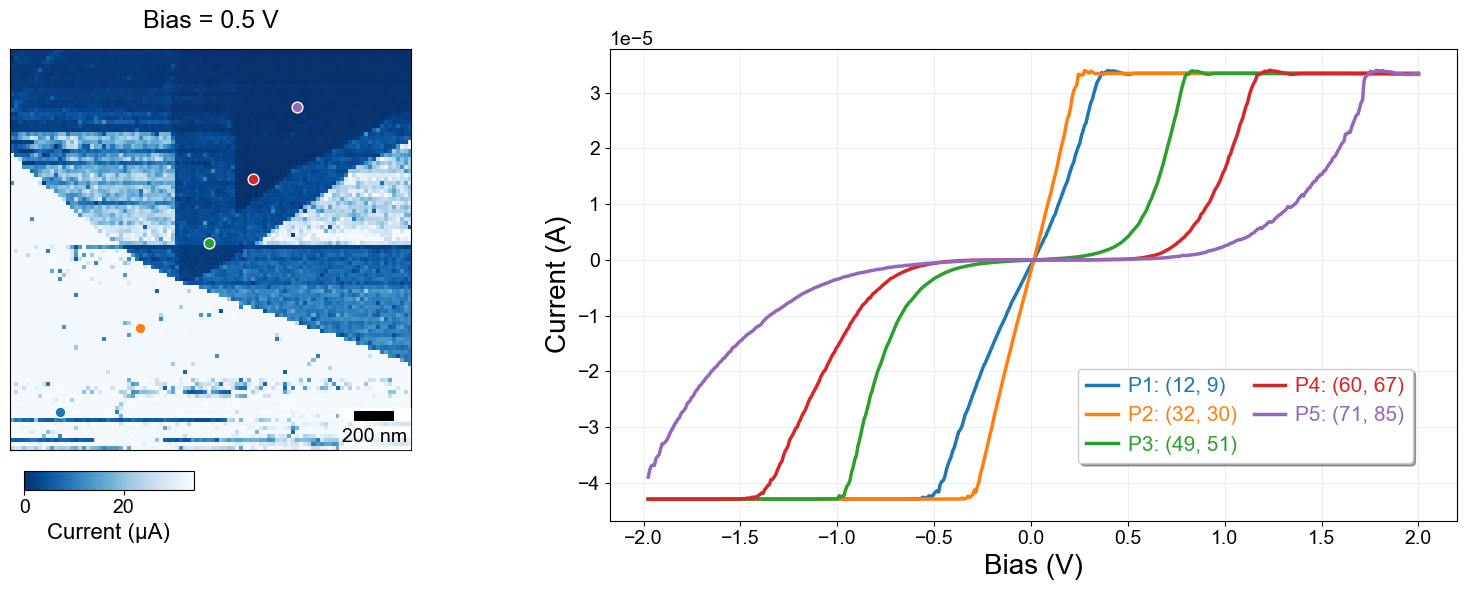

In [4]:
plotter = CorrelatedPlotter(h5map)

# 定義點
points = [(12, 9), (32, 30), (49, 51), (60, 67), (71, 85)]

 # 創建圖表
fig, colors = plotter.create_correlated_plot(
    bias_value=0.5,
    points=points,
    islogy=False,
    start_idx=3,
    colormap='Set2'
)

# 獲取圖表的 axes
ax = fig.axes[1]  # 右圖的 axes

# 移除舊的圖例
if ax.get_legend():
    ax.get_legend().remove()

# 創建新的圖例（完全自定義）
new_legend = ax.legend(
    fontsize=15,  # 字體大小
    loc='lower right',  # 位置
    bbox_to_anchor=(0.96, 0.1),  #height_fraction
    frameon=True,
    fancybox=True,
    shadow=True,
    title='',  # 圖例標題
    title_fontsize=12,
    ncol=2,  # 分為2欄
    columnspacing=0.8,  # 欄間距
    handlelength=1.5,  # 線條長度
    handletextpad=0.5,  # 線條與文字間距
    borderaxespad=0.5  # 邊框與座標軸間距
)

# 設置圖例文字顏色
for i, text in enumerate(new_legend.get_texts()):
    text.set_color(colors[i])

# 保存調整後的圖表

h5map_path = Path(h5map_path)
output_dir = h5map_path.parent / 'plots'
plotter.save_plot_with_timestamp(
    fig, 
    output_dir=output_dir,
    base_name=h5map_path.stem,
    islogy=False
)

ROI Statistics: {'shape': (70, 75), 'mean': np.float64(1.2298530152089143e-05), 'std': np.float64(1.2551300174518345e-05), 'min': np.float64(5.0088602e-08), 'max': np.float64(3.4017052e-05)}
Plot saved to: /home/tim/Documents/AS/data/nanonis2/20240508/2 um 100 pix bias spec map2/plots/2 um 100 pix bias spec map2_20260102_155306_correlated.png


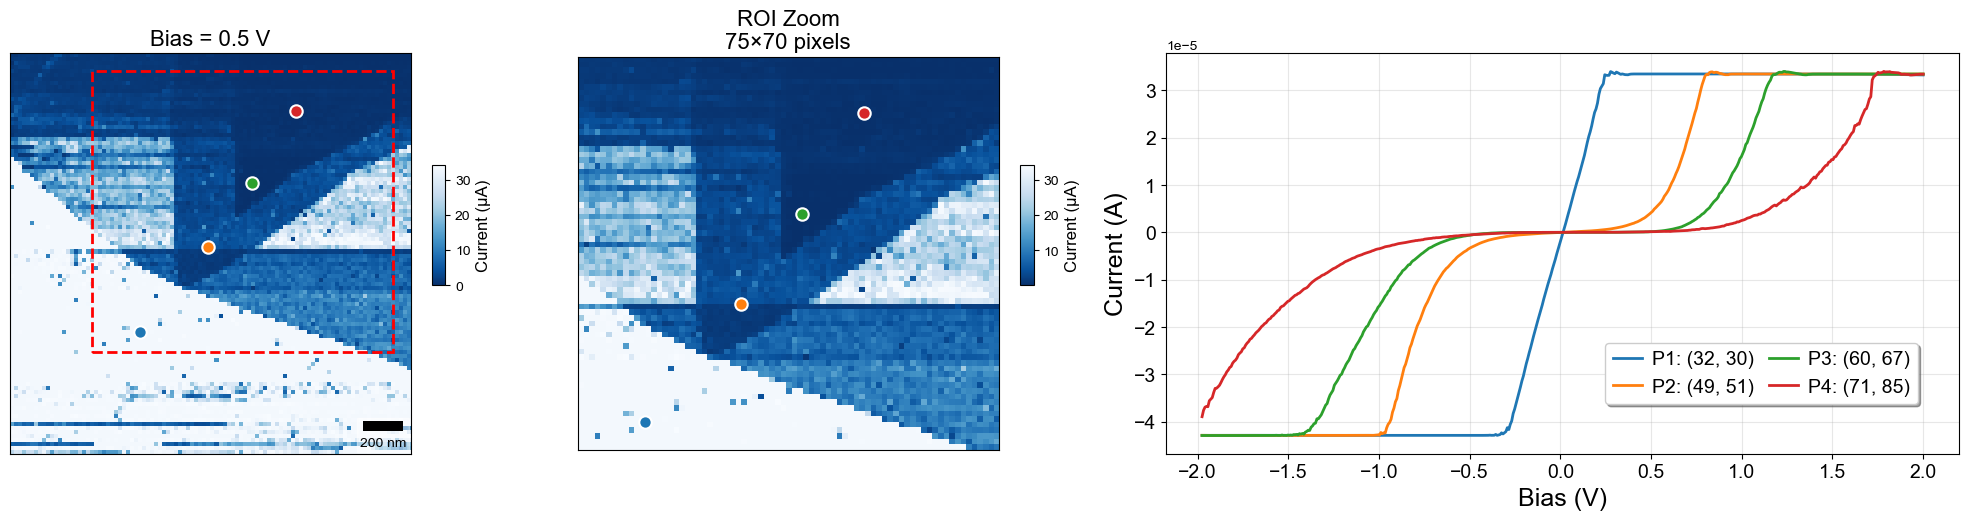

In [6]:
from h5_coplotter import CorrelatedPlotter
from pathlib import Path

# 初始化
h5map = HDF5Analyzer(h5map_path)
plotter = CorrelatedPlotter(h5map)

# 定義點
points = [(32, 30), (49, 51), (60, 67), (71, 85)]

# 定義 ROI 範圍 (x_start, x_end, y_start, y_end)
roi_coords = (20, 95, 25, 95)  # 截取中間區域

# 創建包含 ROI 的三圖
fig, colors, roi_data = plotter.create_correlated_plot_with_roi(
    bias_value=0.5,
    points=points,
    roi_coords=roi_coords,
    islogy=False,
    start_idx=3,
    figsize=(20, 5),
    colormap='Set2'
)

# 也可以獲得 ROI 統計信息
roi_stats = {
    'shape': roi_data.shape,
    'mean': np.mean(roi_data),
    'std': np.std(roi_data),
    'min': np.min(roi_data),
    'max': np.max(roi_data)
}        

print("ROI Statistics:", roi_stats)

# 儲存
h5map_path = Path(h5map_path)
output_dir = h5map_path.parent / 'plots'
plotter.save_plot_with_timestamp(
    fig, 
    output_dir=output_dir,
    base_name=h5map_path.stem,
    islogy=False
)

plt.show()

## Schottkey barrier Fitting


In [31]:
h5map_path

PosixPath('/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5')

In [33]:
from pathlib import Path

# 創建 Path 物件
h5map_path = Path('/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5')

# 常用屬性
print(f"完整路徑: {h5map_path}")
print(f"父目錄: {h5map_path.parent}")
print(f"檔案名稱: {h5map_path.name}")
print(f"主檔名: {h5map_path.stem}")
print(f"副檔名: {h5map_path.suffix}")
print(f"所有父目錄: {list(h5map_path.parents)}")

# 路徑操作
new_path = h5map_path.parent / 'new_file.h5'  # 使用 / 運算子連接路徑
print(f"新路徑: {new_path}")

# 檢查檔案
print(f"檔案存在: {h5map_path.exists()}")
print(f"是檔案: {h5map_path.is_file()}")
print(f"是目錄: {h5map_path.is_dir()}")

# 讀取檔案資訊
print(f"檔案大小 (bytes): {h5map_path.stat().st_size}")
print(f"修改時間: {h5map_path.stat().st_mtime}")

完整路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5
父目錄: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2
檔案名稱: 2 um 100 pix bias spec map2.h5
主檔名: 2 um 100 pix bias spec map2
副檔名: .h5
所有父目錄: [PosixPath('/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'), PosixPath('/home/tim/Documents/AS/data/nanonis2/2024/20240508'), PosixPath('/home/tim/Documents/AS/data/nanonis2/2024'), PosixPath('/home/tim/Documents/AS/data/nanonis2'), PosixPath('/home/tim/Documents/AS/data'), PosixPath('/home/tim/Documents/AS'), PosixPath('/home/tim/Documents'), PosixPath('/home/tim'), PosixPath('/home'), PosixPath('/')]
新路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/new_file.h5
檔案存在: True
是檔案: True
是目錄: False
檔案大小 (bytes): 40012296
修改時間: 1767054675.8479786
